In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = joblib.load("../data/splits.joblib")
model = joblib.load("../models/xgb_model.joblib")

In [2]:
fraud = X_test[y_test == 1]
normal = X_test[y_test == 0].sample(1500, random_state=42)
sample = pd.concat([fraud, normal])

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(sample)

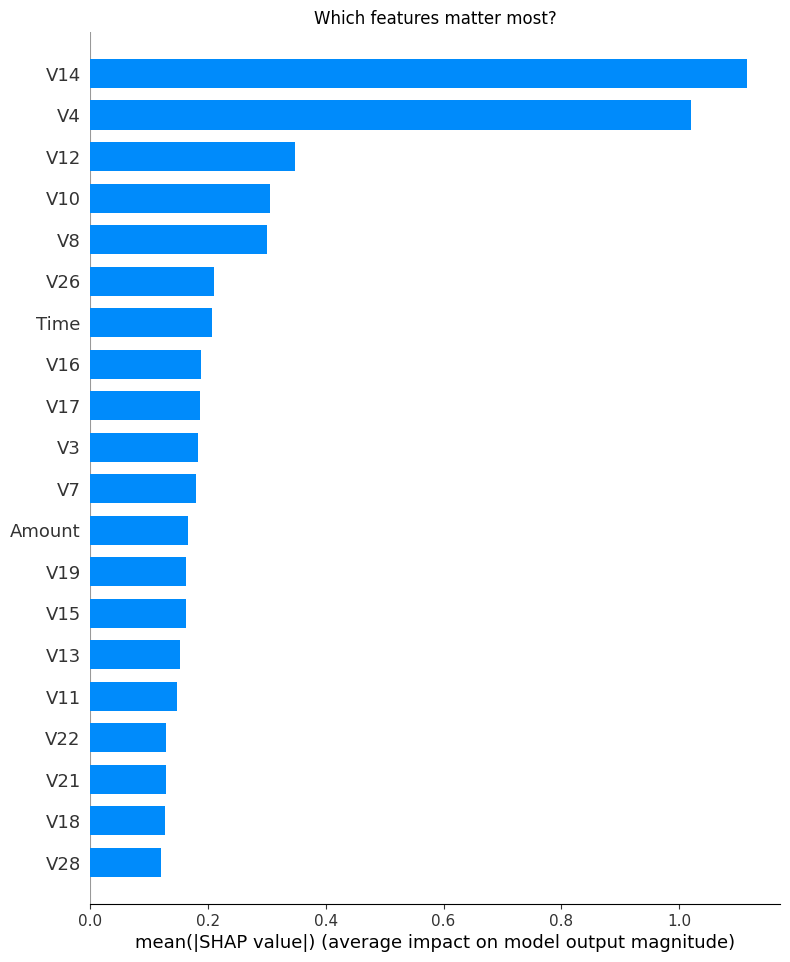

In [3]:
shap.summary_plot(shap_values, sample, plot_type="bar", show=False)
plt.title("Which features matter most?")
plt.savefig("../images/shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

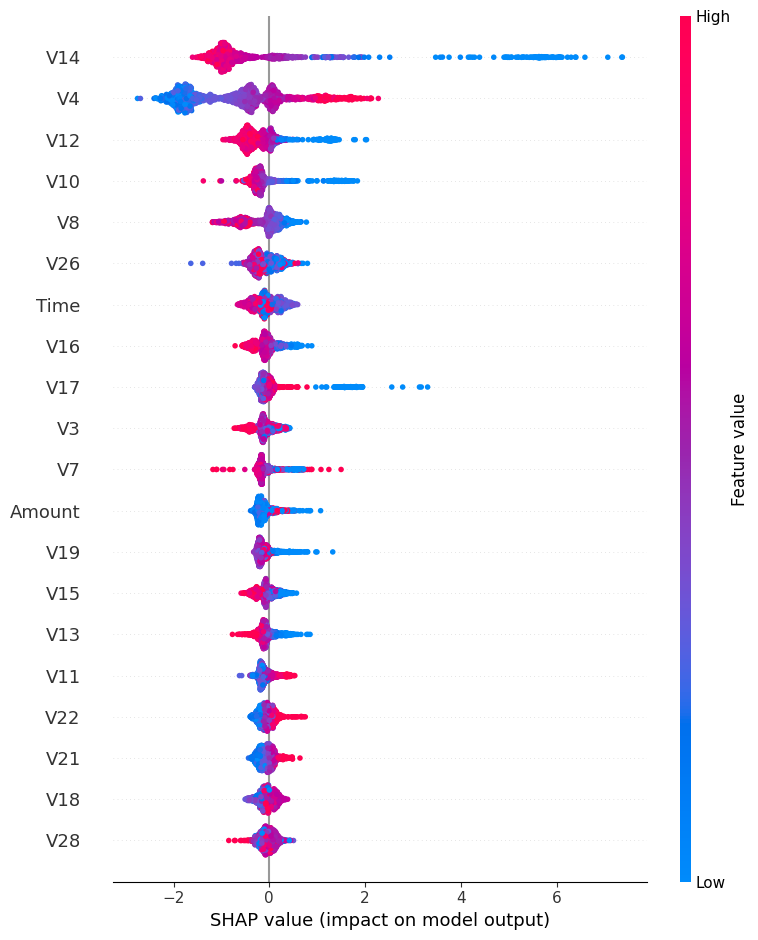

In [4]:
shap.summary_plot(shap_values, sample, show=False)
plt.savefig("../images/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

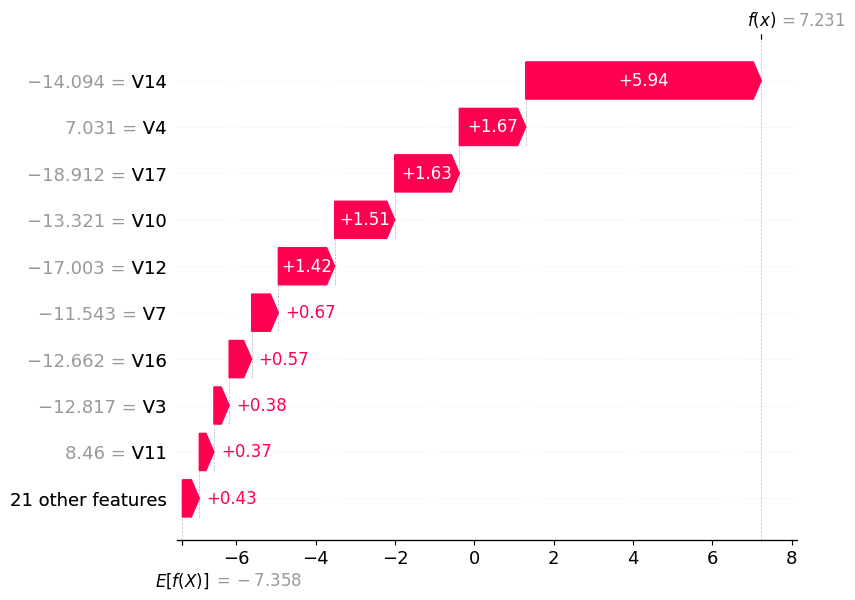

Fraud probability: 0.999 | Actual label: 1


In [5]:
probs = model.predict_proba(sample)[:, 1]
i = int(np.argmax(probs))

shap.plots.waterfall(explainer(sample)[i], show=False)
plt.savefig("../images/shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()
print("Fraud probability:", round(float(probs[i]), 3), "| Actual label:", int(pd.concat([y_test[fraud.index], y_test[normal.index]]).iloc[i]))